<a href="https://colab.research.google.com/github/muskan-512/ML_AP24110011709/blob/main/Diabetes_Prediction_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Prediction Using Machine Learning

## Project Overview

The objective of this project is to develop a machine learning classification system that predicts whether a patient is likely to have diabetes based on medical measurements.

The project uses the Pima Indians Diabetes Dataset and explores different stages of the machine learning pipeline, including exploratory data analysis, data cleaning, preprocessing, feature scaling, model training, model evaluation, and explainable artificial intelligence.

## Objectives

- Understand and analyze the raw dataset.
- Identify and handle missing values, duplicates, and invalid values.
- Perform exploratory data analysis (EDA).
- Apply appropriate data preprocessing techniques.
- Train and compare three classical machine learning algorithms.
- Evaluate models using multiple classification metrics.
- Select the most suitable model.
- Apply SHAP and LIME for model interpretability.

## 1. Importing Required Libraries

Import the Python libraries required for data manipulation, visualization, preprocessing, machine learning, model evaluation, and explainable AI.

In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Machine learning algorithms
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Display settings
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# Reproducibility
RANDOM_STATE = 42

print("All required libraries imported successfully!")


All required libraries imported successfully!


## 2. Uploading the Raw Dataset

In this section, we upload the original CSV file from the local computer into Google Colab. The original dataset will be loaded without applying any cleaning or preprocessing operations.

In [2]:

from google.colab import files

uploaded = files.upload()

# Get uploaded filename
file_name = next(iter(uploaded))

print("Uploaded file:", file_name)


Saving pima-indians-diabetes Dataset.txt to pima-indians-diabetes Dataset.txt
Uploaded file: pima-indians-diabetes Dataset.txt


In [3]:

# Expected dataset columns
columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

# Load dataset and handle both header formats
df = pd.read_csv(file_name)

if 'Outcome' not in df.columns:
    df = pd.read_csv(file_name, header=None, names=columns)

print("Raw dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Raw dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:

print("First 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nDataset Dimensions:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)


First 5 Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Last 5 Records:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0



Dataset Dimensions:
(768, 9)

Column Names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Data Types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


## 3. Dataset Information and Structure

The first step in data quality analysis is to understand the structure of the dataset. We will examine the number of records, features, data types, and memory usage to identify any structural issues.

In [5]:

# Dataset information
print("DATASET INFORMATION")
print("-" * 50)

df.info()

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Total Records:", df.shape[0] * df.shape[1])


DATASET INFORMATION
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Number of Rows: 768
Number of Columns: 9
Total Records: 6912


## 4. Statistical Summary

Descriptive statistical analysis helps us understand the distribution and characteristics of numerical features. We will examine the mean, standard deviation, minimum, maximum, and quartile values to identify unusual observations.

In [6]:

# Statistical summary
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## 5. Missing Value Analysis

Missing values can affect the performance of machine learning models. We will identify the number and percentage of missing values in each column before deciding on an appropriate treatment method.

In [7]:

# Missing value count
missing_count = df.isnull().sum()

# Missing value percentage
missing_percentage = (missing_count / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing_count,
    'Missing Percentage': missing_percentage
})

display(missing_table)

print("Total Missing Values:", df.isnull().sum().sum())


,Missing Values,Missing Percentage
Pregnancies,0,0.0
Glucose,0,0.0
BloodPressure,0,0.0
SkinThickness,0,0.0
Insulin,0,0.0
BMI,0,0.0
DiabetesPedigreeFunction,0,0.0
Age,0,0.0
Outcome,0,0.0


Total Missing Values: 0


## 6. Duplicate Record Analysis

Duplicate records may introduce repeated observations and affect model evaluation. We will identify exact duplicate rows and calculate their total number before deciding whether removal is necessary.

In [8]:

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Display duplicate records
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))
else:
    print("No duplicate records found.")


Total Duplicate Records: 0
No duplicate records found.


## 7. Invalid Zero Value Analysis

Although the dataset does not necessarily contain explicit missing values, some medical measurements contain zero values that may represent unrecorded information.

For example, glucose, blood pressure, skin thickness, insulin, and BMI measurements should not normally be zero. We will investigate these values before replacing them with missing-value indicators.

Zero pregnancies and zero values in the diabetes pedigree function will be retained.

In [9]:

# Features where zero may represent missing measurements
zero_missing_features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Count zero values
zero_counts = (df[zero_missing_features] == 0).sum()

zero_table = pd.DataFrame({
    'Zero Values': zero_counts,
    'Percentage': (zero_counts / len(df)) * 100
})

display(zero_table)

print("Total questionable zero values:",
      (df[zero_missing_features] == 0).sum().sum())


,Zero Values,Percentage
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292


Total questionable zero values: 652


## 8. Target Variable Distribution

The target variable is Outcome, where 0 represents non-diabetic observations and 1 represents diabetic observations.

We will examine the distribution of both classes to identify potential class imbalance, which may influence model performance and evaluation.

Target Variable Distribution:


,count
Outcome,
0,500
1,268



Target Class Percentage:


,proportion
Outcome,
0,65.1
1,34.9


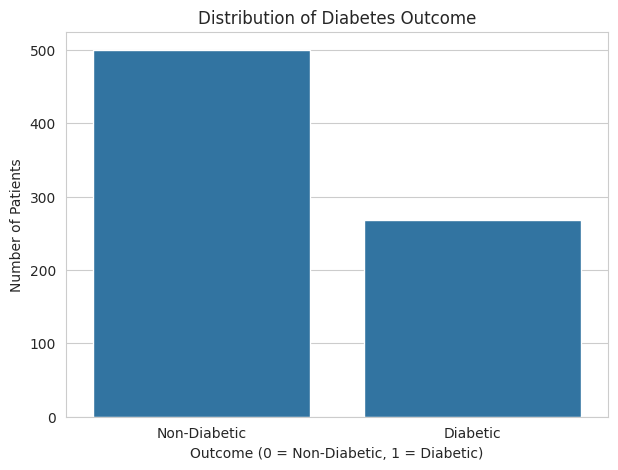

In [10]:

# Target class count
print("Target Variable Distribution:")
display(df['Outcome'].value_counts().sort_index())

# Target class percentage
print("\nTarget Class Percentage:")
display(
    (df['Outcome'].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Outcome')

plt.title('Distribution of Diabetes Outcome')
plt.xlabel('Outcome (0 = Non-Diabetic, 1 = Diabetic)')
plt.ylabel('Number of Patients')

plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.show()


## 9. Data Consistency and Validity Checks

We will check whether numerical features contain negative values, infinite values, or unexpected target labels. These checks help identify potential data-quality problems before preprocessing.

In [11]:

# Check infinite values
print("Infinite values in dataset:")
print(np.isinf(df.select_dtypes(include=np.number)).sum())

# Check negative values
print("\nNegative values in each column:")
display((df.select_dtypes(include=np.number) < 0).sum())

# Check target labels
print("\nUnique target values:")
print(df['Outcome'].unique())

# Check unexpected target labels
print("\nInvalid target labels:",
      ~df['Outcome'].isin([0, 1]).all())


Infinite values in dataset:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Negative values in each column:


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Unique target values:
[1 0]

Invalid target labels: False


In [12]:

print("=" * 55)
print("         INITIAL DATA QUALITY SUMMARY")
print("=" * 55)

print("Total Records:", len(df))
print("Total Features:", df.shape[1] - 1)
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("Questionable Zero Values:",
      (df[zero_missing_features] == 0).sum().sum())

print("Diabetic Patients:", (df['Outcome'] == 1).sum())
print("Non-Diabetic Patients:", (df['Outcome'] == 0).sum())

print("=" * 55)


         INITIAL DATA QUALITY SUMMARY
Total Records: 768
Total Features: 8
Missing Values: 0
Duplicate Records: 0
Questionable Zero Values: 652
Diabetic Patients: 268
Non-Diabetic Patients: 500


## 10. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the characteristics, distribution, and relationships among the dataset features.

Before visualization, we create a separate copy of the raw dataset. Physiologically implausible zero measurements in selected medical columns are temporarily converted into NaN values for analysis. The original dataset remains unchanged.

In [13]:

# Create a separate copy for EDA
df_eda = df.copy()

# Convert questionable zeros into NaN for analysis only
zero_missing_features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df_eda[zero_missing_features] = (
    df_eda[zero_missing_features].replace(0, np.nan)
)

print("EDA dataset created successfully!")
print("Original dataset shape:", df.shape)
print("EDA dataset shape:", df_eda.shape)

display(df_eda.head())


EDA dataset created successfully!
Original dataset shape: (768, 9)
EDA dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 11. Feature Distribution Analysis

Feature distribution analysis helps us understand how numerical values are spread across the dataset. We will examine the distribution of all eight independent variables using histograms and kernel density curves.

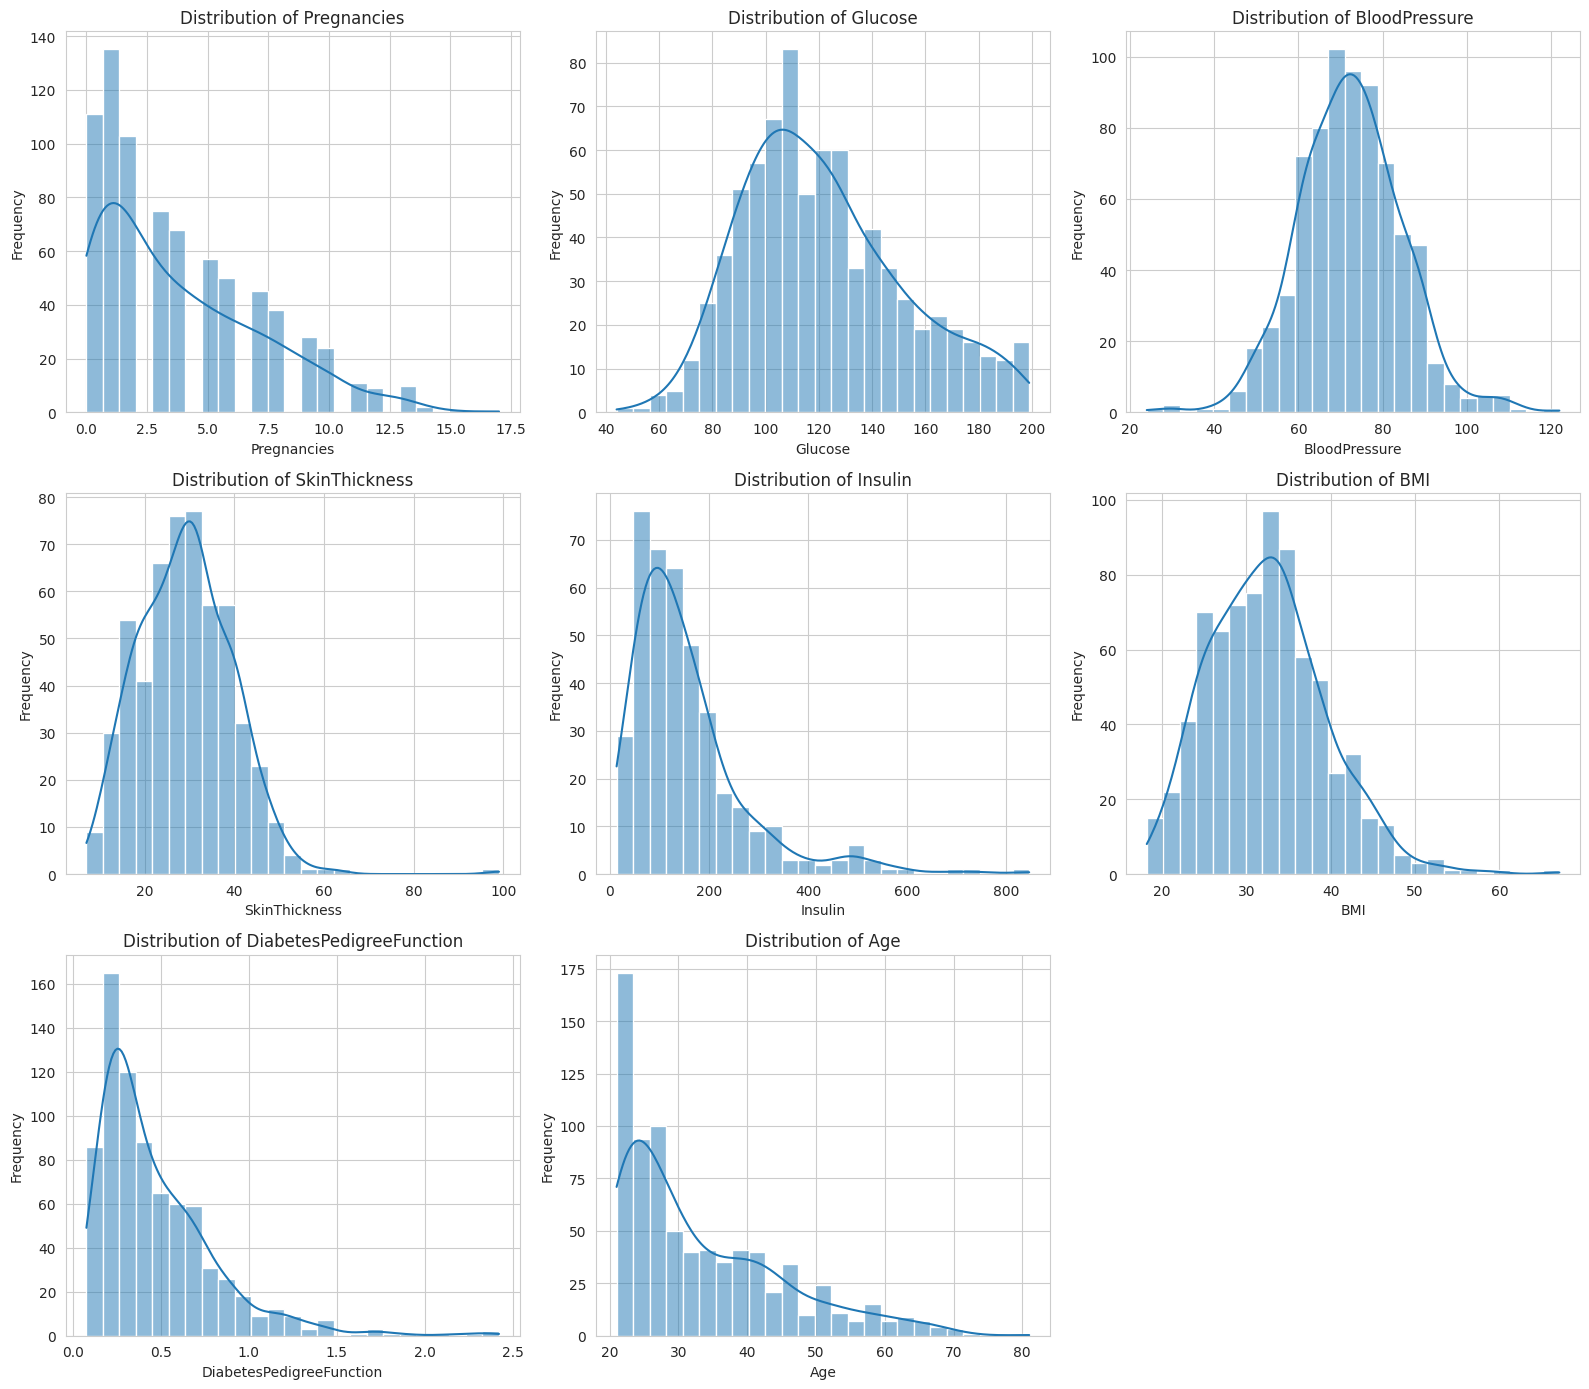

In [14]:

# Select independent numerical features
features = df_eda.drop(columns=['Outcome']).columns

# Plot histograms
plt.figure(figsize=(16, 14))

for i, col in enumerate(features, 1):
    plt.subplot(3, 3, i)

    sns.histplot(
        data=df_eda,
        x=col,
        kde=True,
        bins=25
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


## 12. Outlier Detection Using Box Plots

Box plots are used to visualize the distribution of numerical features and identify potential outliers. Outliers are observations that lie outside the typical range of a feature.

We will use the Interquartile Range (IQR) method to identify potential outliers. These observations will be investigated rather than automatically removed.

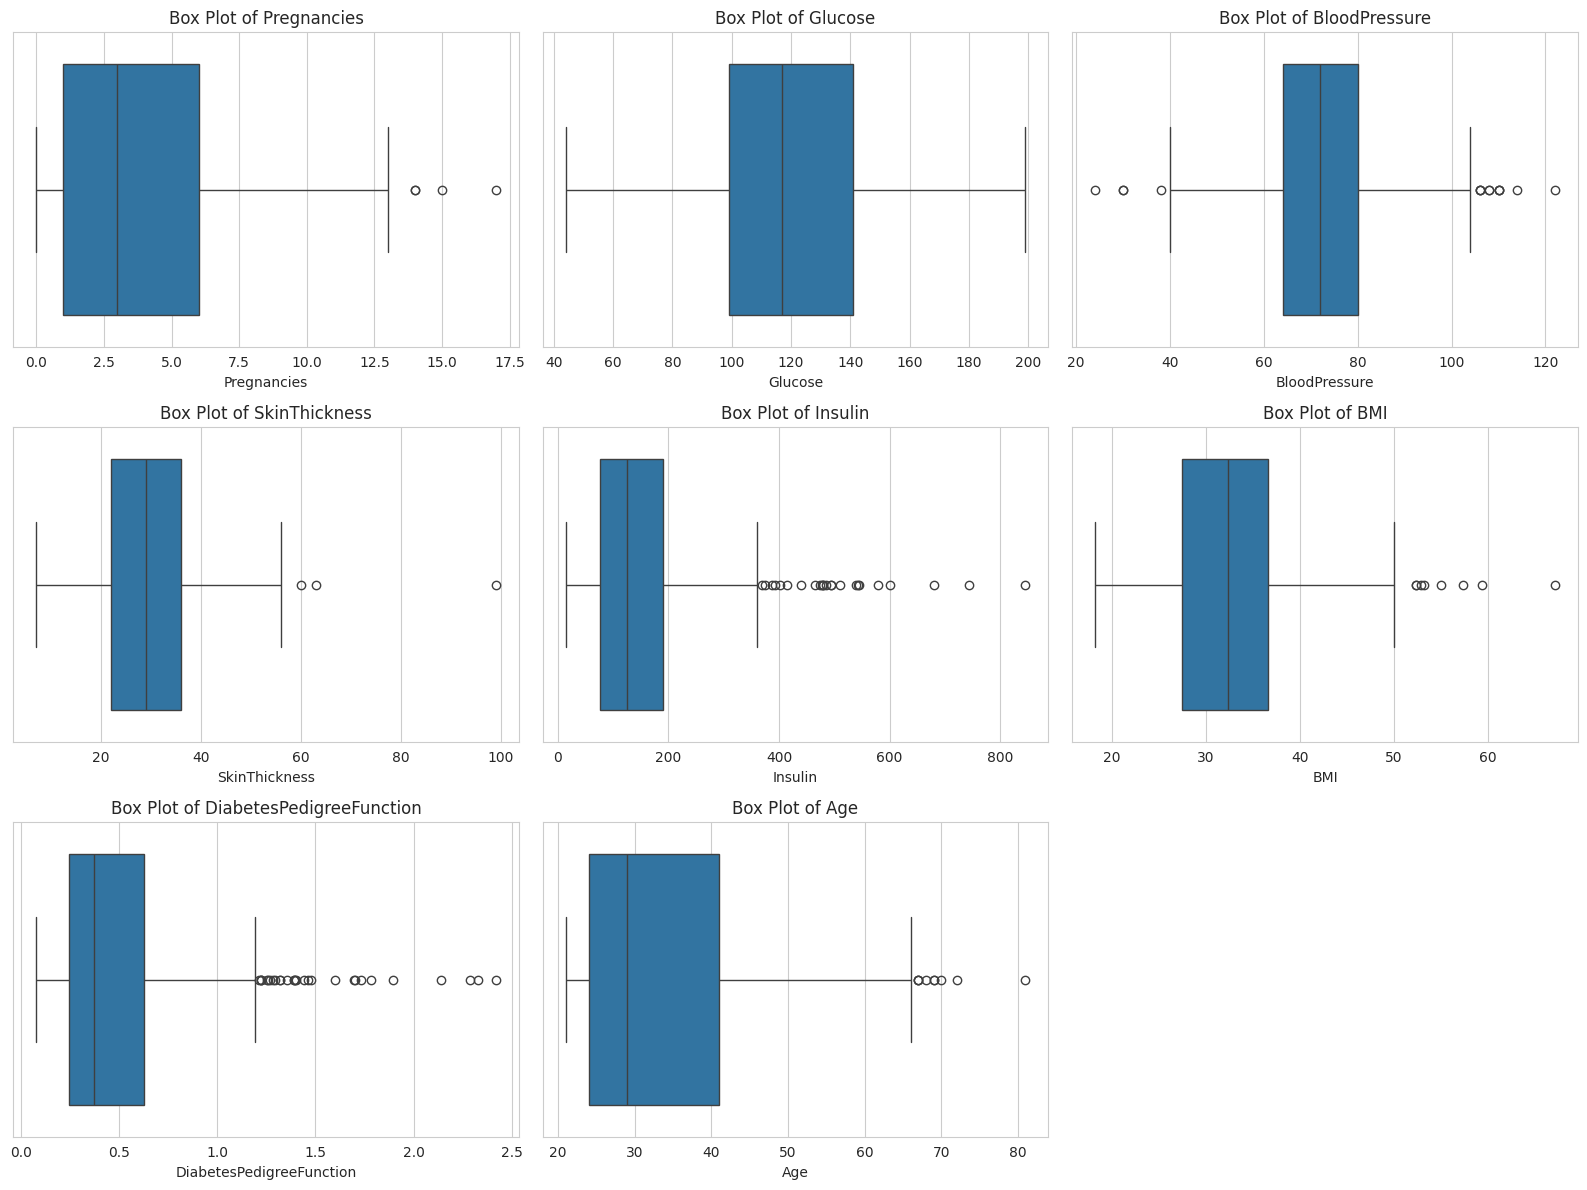

In [15]:

plt.figure(figsize=(16, 12))

for i, col in enumerate(features, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(data=df_eda, x=col)

    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()


In [16]:

outlier_results = []

for col in features:

    Q1 = df_eda[col].quantile(0.25)
    Q3 = df_eda[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df_eda[col] < lower_bound) |
        (df_eda[col] > upper_bound)
    ).sum()

    outlier_results.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outliers
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)


,Feature,Lower Bound,Upper Bound,Outlier Count
0,Pregnancies,-6.500,13.500,4
1,Glucose,36.000,204.000,0
2,BloodPressure,40.000,104.000,14
3,SkinThickness,1.000,57.000,3
4,Insulin,-94.375,360.625,24
5,BMI,13.850,50.250,8
6,DiabetesPedigreeFunction,-0.330,1.200,29
7,Age,-1.500,66.500,9


## 13. Correlation Analysis Using Heatmap

Correlation analysis helps us understand the strength and direction of relationships between numerical variables.

The Pearson correlation coefficient ranges from -1 to +1:

- +1 indicates perfect positive correlation.
- -1 indicates perfect negative correlation.
- 0 indicates little or no linear correlation.

We will use a heatmap to visualize the correlation between independent features and the diabetes outcome.

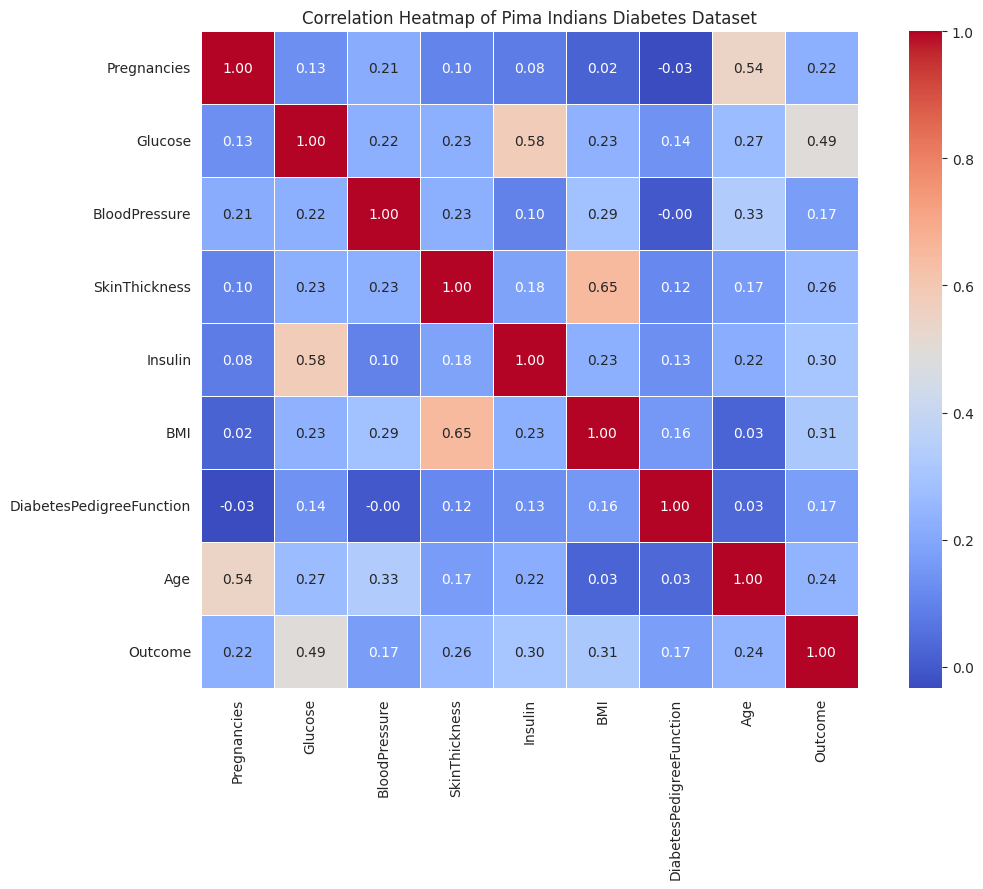

In [17]:

# Calculate correlation matrix
correlation_matrix = df_eda.corr()

# Visualize correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title('Correlation Heatmap of Pima Indians Diabetes Dataset')
plt.tight_layout()
plt.show()


## 14. Feature Analysis Based on Diabetes Outcome

In this section, we compare the distribution of each medical feature between diabetic and non-diabetic patients.

This analysis helps us identify which features show noticeable differences between the two outcome groups.

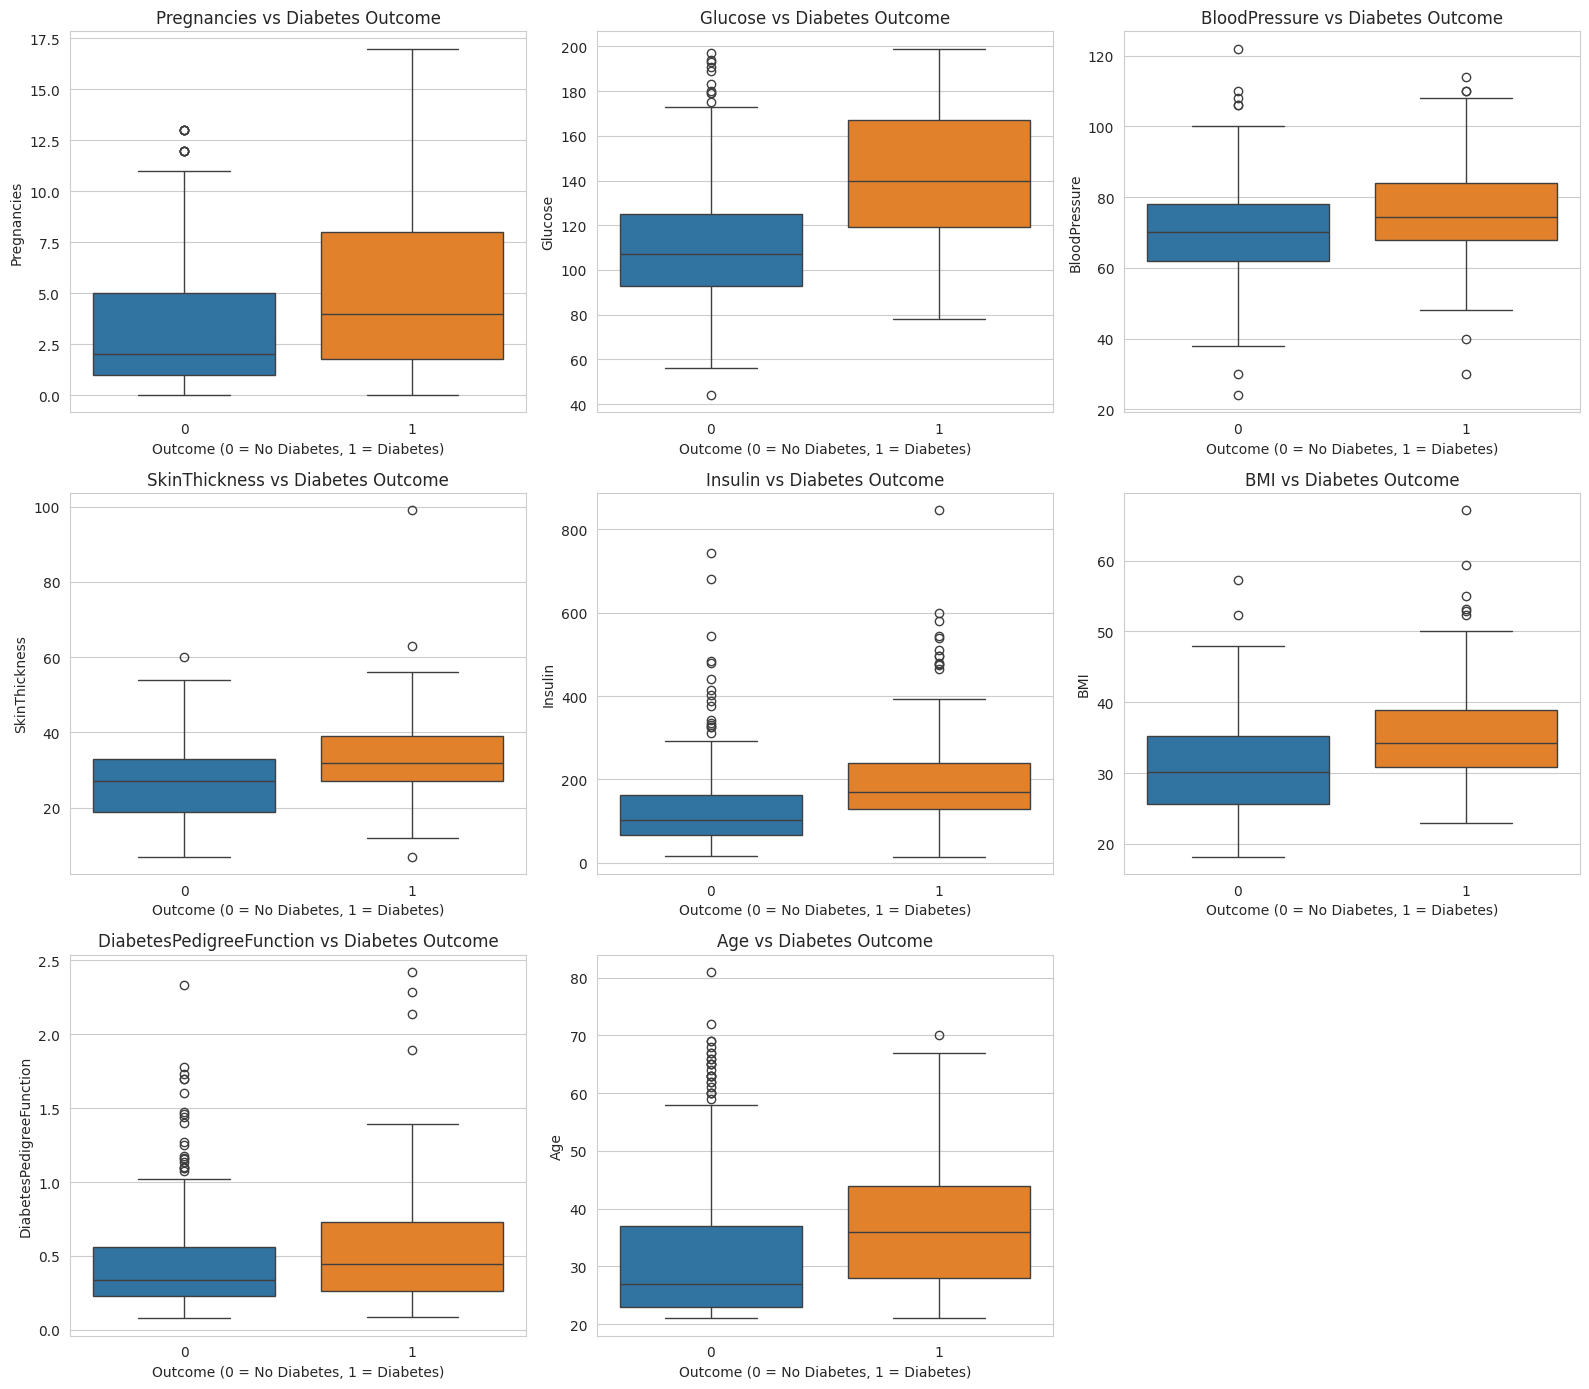

In [18]:

# Compare each feature across target classes
plt.figure(figsize=(16, 14))

for i, col in enumerate(features, 1):
    plt.subplot(3, 3, i)

    sns.boxplot(
        data=df_eda,
        x='Outcome',
        y=col,
        hue='Outcome',
        legend=False
    )

    plt.title(f'{col} vs Diabetes Outcome')
    plt.xlabel('Outcome (0 = No Diabetes, 1 = Diabetes)')

plt.tight_layout()
plt.show()


## 15. Pair Plot Analysis

A pair plot displays relationships between multiple numerical features using scatter plots and distribution plots.

We will select important medical variables to understand their pairwise relationships and observe how diabetic and non-diabetic observations are distributed.

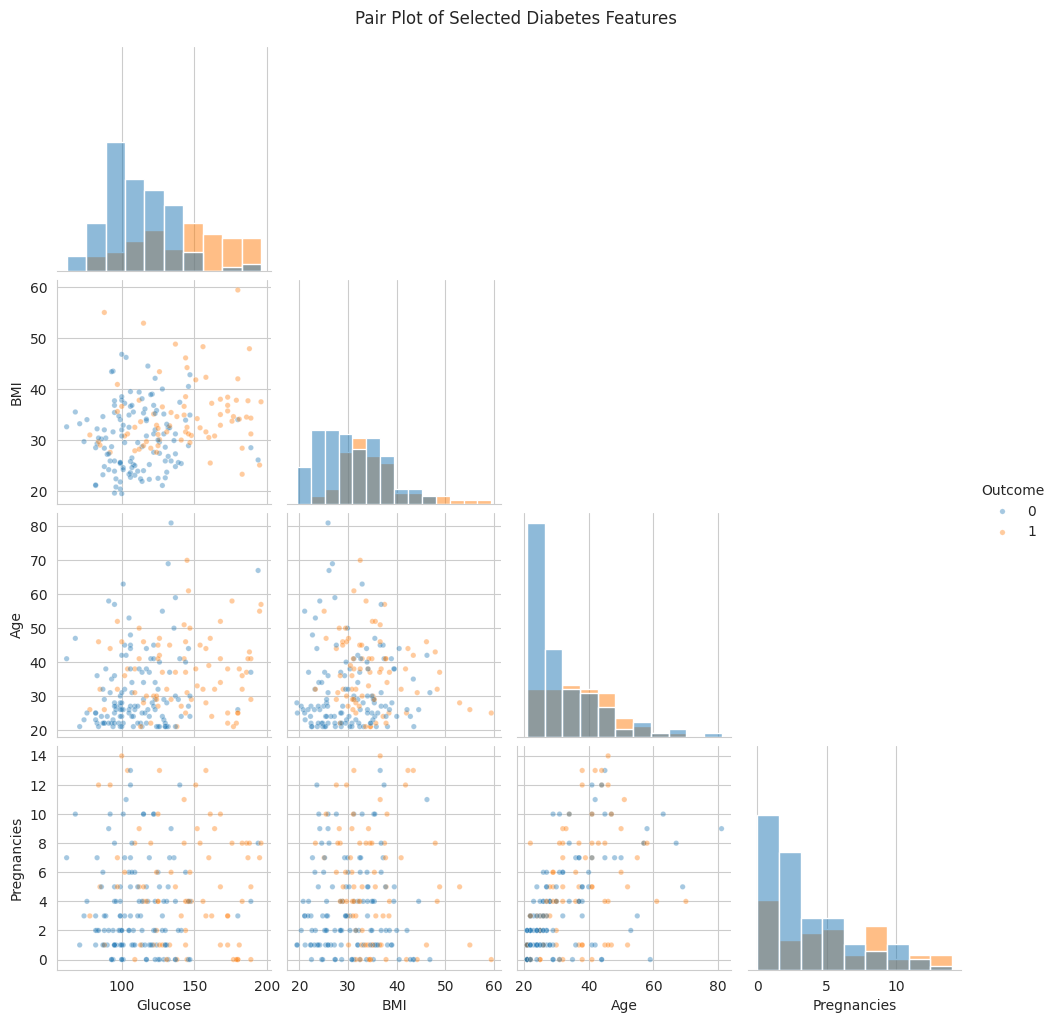

In [19]:

# Select important features
selected_features = [
    'Glucose',
    'BMI',
    'Age',
    'Pregnancies',
    'Outcome'
]

# Randomly select 200 records
pairplot_sample = df_eda[selected_features].dropna().sample(
    n=min(200, len(df_eda[selected_features].dropna())),
    random_state=42
)

# Generate a lightweight pair plot
sns.pairplot(
    pairplot_sample,
    hue='Outcome',
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.4, 's': 15}
)

plt.suptitle('Pair Plot of Selected Diabetes Features', y=1.02)
plt.show()


## 16. Feature Relationship with Diabetes Outcome

We will calculate the Pearson correlation between each numerical feature and the target variable. This provides an initial indication of the strength and direction of linear relationships with the diabetes outcome.

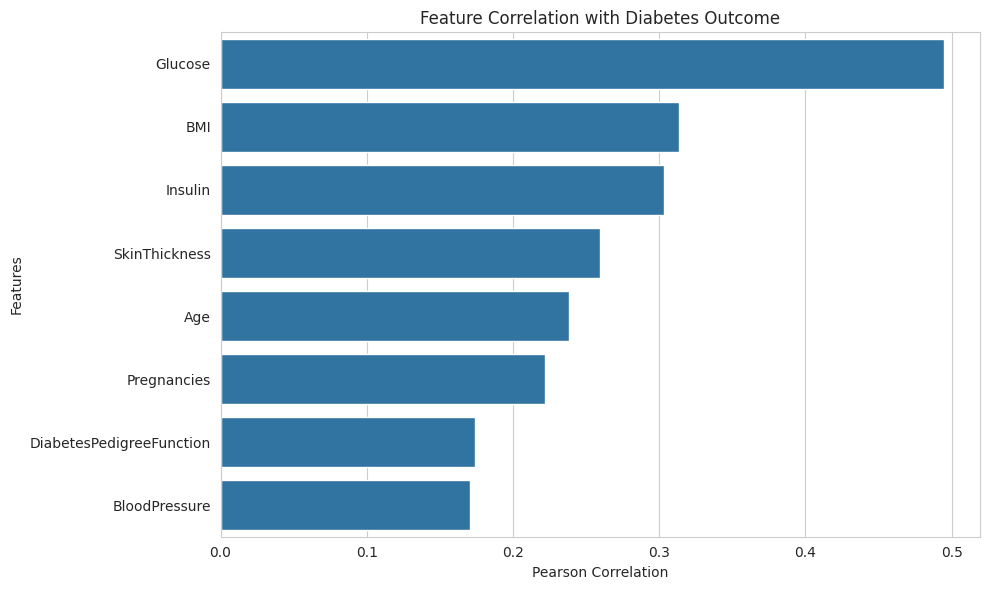

,Correlation with Outcome
Glucose,0.494650
BMI,0.313680
Insulin,0.303454
SkinThickness,0.259491
Age,0.238356
Pregnancies,0.221898
DiabetesPedigreeFunction,0.173844
BloodPressure,0.170589


In [20]:

target_correlation = (
    df_eda.corr()['Outcome']
    .drop('Outcome')
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index
)

plt.title('Feature Correlation with Diabetes Outcome')
plt.xlabel('Pearson Correlation')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

display(target_correlation.to_frame('Correlation with Outcome'))


## 17. Exploratory Data Analysis – Observations

The exploratory data analysis provides an understanding of the distribution, relationships, and potential outliers in the Pima Indians Diabetes Dataset.

The analysis focuses on:

1. Understanding the distribution of medical features.
2. Identifying skewness and potential outliers.
3. Examining correlations between features.
4. Comparing medical measurements across diabetes outcome groups.
5. Identifying features that may contribute useful predictive information.

The findings from this analysis will guide the data cleaning and preprocessing stages.

## 18. Data Cleaning

Data cleaning is performed to improve the quality and consistency of the dataset before model training.

In the Pima Indians Diabetes Dataset, zero values in certain medical measurement columns may represent missing or unrecorded information rather than actual measurements.

We will replace these questionable zero values with missing-value indicators (NaN). The original raw dataset will remain unchanged.

In [21]:

# Create a separate cleaned dataset
df_clean = df.copy()

# Features where zero represents potentially missing measurements
zero_missing_features = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

# Replace questionable zeros with NaN
df_clean[zero_missing_features] = (
    df_clean[zero_missing_features].replace(0, np.nan)
)

print("Questionable zero values converted to NaN.")
print("Cleaned dataset shape:", df_clean.shape)

display(df_clean.head())


Questionable zero values converted to NaN.
Cleaned dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 19. Missing Value Analysis After Data Cleaning

After identifying questionable zero values, we will examine the updated missing-value count and percentage for each feature. This helps us determine the appropriate imputation strategy.

In [22]:

missing_summary = pd.DataFrame({
    'Missing Count': df_clean.isnull().sum(),
    'Missing Percentage': (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

print(
    "Total missing values after zero replacement:",
    df_clean.isnull().sum().sum()
)


,Missing Count,Missing Percentage
Pregnancies,0,0.00
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43
DiabetesPedigreeFunction,0,0.00
Age,0,0.00
Outcome,0,0.00


Total missing values after zero replacement: 652


## 20. Missing Value Visualization

A missing-value heatmap helps visualize the distribution of missing observations across different features and records.

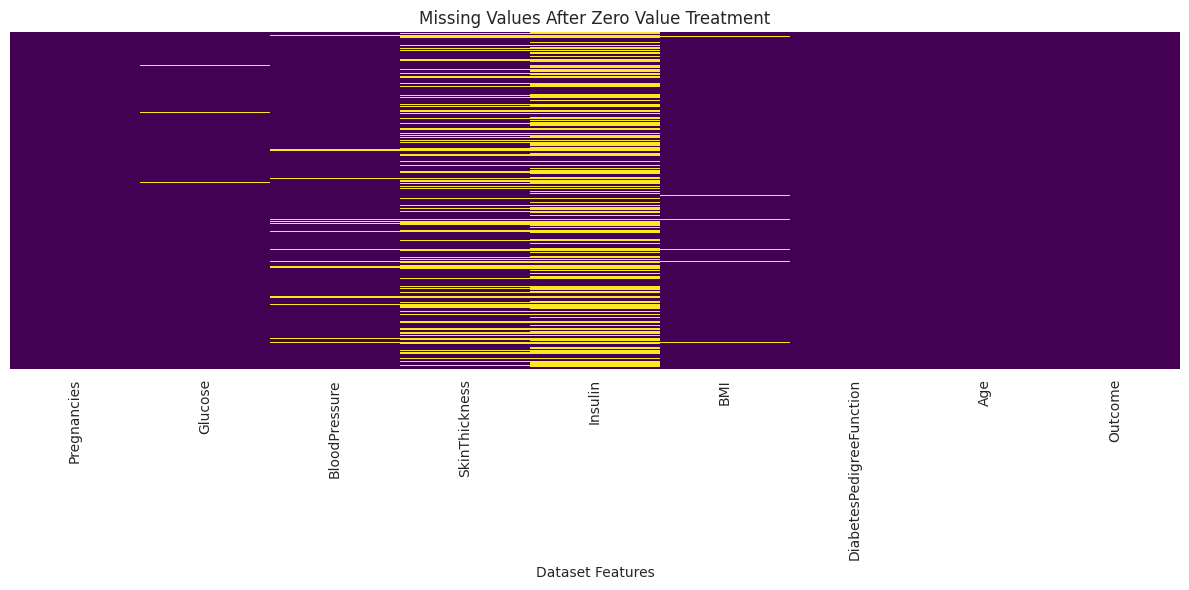

In [23]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values After Zero Value Treatment')
plt.xlabel('Dataset Features')
plt.tight_layout()
plt.show()


In [24]:

# Separate independent variables and target variable

X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

print("Independent variables shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())


Independent variables shape: (768, 8)
Target variable shape: (768,)

Target classes:
Outcome
0    500
1    268
Name: count, dtype: int64


## 21. Splitting the Dataset into Training and Testing Sets

The dataset is divided into training and testing subsets.

- Training set (80%): Used to train machine learning models.
- Testing set (20%): Used to evaluate model performance on unseen observations.

We use stratified sampling to preserve the original proportion of diabetic and non-diabetic observations in both subsets.

A random state of 42 ensures reproducibility.

In [25]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))


Training data shape: (614, 8)
Testing data shape: (154, 8)

Training target distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing target distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


## 22. Missing Value Imputation

Missing values are handled using median imputation.

The median value of each feature is calculated from the training dataset only. The same imputation values are then applied to the testing dataset to prevent data leakage.

In [26]:

from sklearn.impute import SimpleImputer

# Initialize median imputer
imputer = SimpleImputer(strategy='median')

# Fit on training data and transform
X_train_imputed = imputer.fit_transform(X_train)

# Transform testing data using training medians
X_test_imputed = imputer.transform(X_test)

# Convert back to DataFrames
X_train_imputed = pd.DataFrame(
    X_train_imputed,
    columns=X.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X.columns,
    index=X_test.index
)

print("Missing values handled successfully!")

print("Training missing values:",
      X_train_imputed.isnull().sum().sum())

print("Testing missing values:",
      X_test_imputed.isnull().sum().sum())


Missing values handled successfully!
Training missing values: 0
Testing missing values: 0


## 23. Feature Scaling Using StandardScaler

Feature scaling transforms numerical features to a comparable scale.

We use StandardScaler to standardize features based on their training-set mean and standard deviation.

Feature scaling is particularly important for KNN because it uses distance calculations. It is also useful for Gaussian Naive Bayes. Decision Trees do not require feature scaling.

In [27]:

from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit scaler on training data
X_train_scaled = scaler.fit_transform(X_train_imputed)

# Transform testing data
X_test_scaled = scaler.transform(X_test_imputed)

# Convert to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X.columns,
    index=X_test.index
)

print("Feature scaling completed successfully!")

display(X_train_scaled.head())


Feature scaling completed successfully!


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769694,0.310794,-0.792169
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417714,-0.116439,0.561034
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359576,-0.764862,-0.707594
46,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.403048,0.262314,-0.369293
682,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782163,-0.337630,-0.961320


## 24. Final Preprocessing Verification

In this section, we verify that the training and testing datasets contain no missing values and that feature scaling has been applied correctly.

In [28]:

print("=" * 55)
print("       PREPROCESSING VERIFICATION")
print("=" * 55)

print("\nTraining data:")
print("Shape:", X_train_scaled.shape)
print("Missing values:", X_train_scaled.isnull().sum().sum())

print("\nTesting data:")
print("Shape:", X_test_scaled.shape)
print("Missing values:", X_test_scaled.isnull().sum().sum())

print("\nTraining feature means (approximately zero):")
display(X_train_scaled.mean().round(3))

print("\nTraining feature standard deviations (approximately one):")
display(X_train_scaled.std().round(3))

print("=" * 55)


       PREPROCESSING VERIFICATION

Training data:
Shape: (614, 8)
Missing values: 0

Testing data:
Shape: (154, 8)
Missing values: 0

Training feature means (approximately zero):


,0
Pregnancies,-0.0
Glucose,-0.0
BloodPressure,0.0
SkinThickness,-0.0
Insulin,-0.0
BMI,0.0
DiabetesPedigreeFunction,-0.0
Age,-0.0



Training feature standard deviations (approximately one):


,0
Pregnancies,1.001
Glucose,1.001
BloodPressure,1.001
SkinThickness,1.001
Insulin,1.001
BMI,1.001
DiabetesPedigreeFunction,1.001
Age,1.001


## 25. Target Variable Encoding Verification

The target variable already contains binary numerical labels:

- 0 represents non-diabetic.
- 1 represents diabetic.

Therefore, additional label encoding is not required. We will verify the target labels before model training.

In [29]:

print("Unique target labels:", sorted(y.unique()))

print("\nTarget mapping:")
print("0 = Non-Diabetic")
print("1 = Diabetic")

print("\nTraining target classes:")
print(sorted(y_train.unique()))

print("\nTesting target classes:")
print(sorted(y_test.unique()))


Unique target labels: [np.int64(0), np.int64(1)]

Target mapping:
0 = Non-Diabetic
1 = Diabetic

Training target classes:
[np.int64(0), np.int64(1)]

Testing target classes:
[np.int64(0), np.int64(1)]


## 26. Machine Learning Model Development

In this section, three classical machine learning classification algorithms are implemented:

1. Gaussian Naive Bayes
2. K-Nearest Neighbors (KNN)
3. Decision Tree Classifier

These algorithms are selected to compare probabilistic, distance-based, and tree-based classification approaches.

All models will use the same training and testing split to ensure a fair comparison.

In [30]:

# Import machine learning algorithms
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Initialize models
models = {
    'Gaussian Naive Bayes': GaussianNB(),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    )
}

print("Three machine learning models initialized successfully!")


Three machine learning models initialized successfully!


## 27. Model Training

Model training involves providing the training dataset to each machine learning algorithm so that it can learn patterns and relationships between medical measurements and diabetes outcomes.

Each model is trained using the same training dataset. Scaled features are used for all three models to maintain a consistent preprocessing workflow.

In [31]:

# Dictionary to store trained models
trained_models = {}

# Train all models
for model_name, model in models.items():

    model.fit(X_train_scaled, y_train)

    trained_models[model_name] = model

    print(f"{model_name} trained successfully!")

print("\nAll three models have been trained.")


Gaussian Naive Bayes trained successfully!
K-Nearest Neighbors trained successfully!
Decision Tree trained successfully!

All three models have been trained.


## 28. Model Predictions

After training, each model is used to predict diabetes outcomes for the testing dataset.

The predicted values are compared with actual outcomes to evaluate classification performance on previously unseen observations.

In [32]:

# Store predictions
predictions = {}

# Store predicted probabilities
prediction_probabilities = {}

for model_name, model in trained_models.items():

    # Predict class labels
    y_pred = model.predict(X_test_scaled)

    # Predict probabilities for positive class
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    predictions[model_name] = y_pred

    prediction_probabilities[model_name] = y_prob

    print(f"\n{model_name}")
    print("Predictions:", y_pred[:10])
    print("Probabilities:", y_prob[:10].round(3))



Gaussian Naive Bayes
Predictions: [1 0 0 0 0 0 1 1 0 1]
Probabilities: [0.511 0.363 0.187 0.101 0.014 0.046 0.752 0.995 0.01  0.988]

K-Nearest Neighbors
Predictions: [1 0 0 1 0 0 0 1 0 1]
Probabilities: [0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6]

Decision Tree
Predictions: [1 0 0 1 1 0 0 1 0 1]
Probabilities: [1. 0. 0. 1. 1. 0. 0. 1. 0. 1.]


## 29. Model Evaluation Using Classification Metrics

The performance of each machine learning model is evaluated using multiple classification metrics.

The following metrics are calculated:

- Accuracy: Measures the proportion of correctly classified observations.
- Precision: Measures how many predicted diabetic cases are actually diabetic.
- Recall: Measures how many actual diabetic cases are correctly identified.
- F1-score: Provides a balance between precision and recall.
- ROC-AUC: Measures the model's ability to distinguish between diabetic and non-diabetic observations.

These metrics provide a more comprehensive evaluation than accuracy alone.

In [33]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store evaluation results
results = []

for model_name in trained_models:

    y_pred = predictions[model_name]
    y_prob = prediction_probabilities[model_name]

    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gaussian Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
1,K-Nearest Neighbors,0.7532,0.6600,0.6111,0.6346,0.7899
2,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357


## 30. Comparative Performance Visualization

A grouped bar chart is used to compare the performance of all three machine learning algorithms across accuracy, precision, recall, F1-score, and ROC-AUC.

This visualization helps identify differences in predictive performance across the selected evaluation metrics.

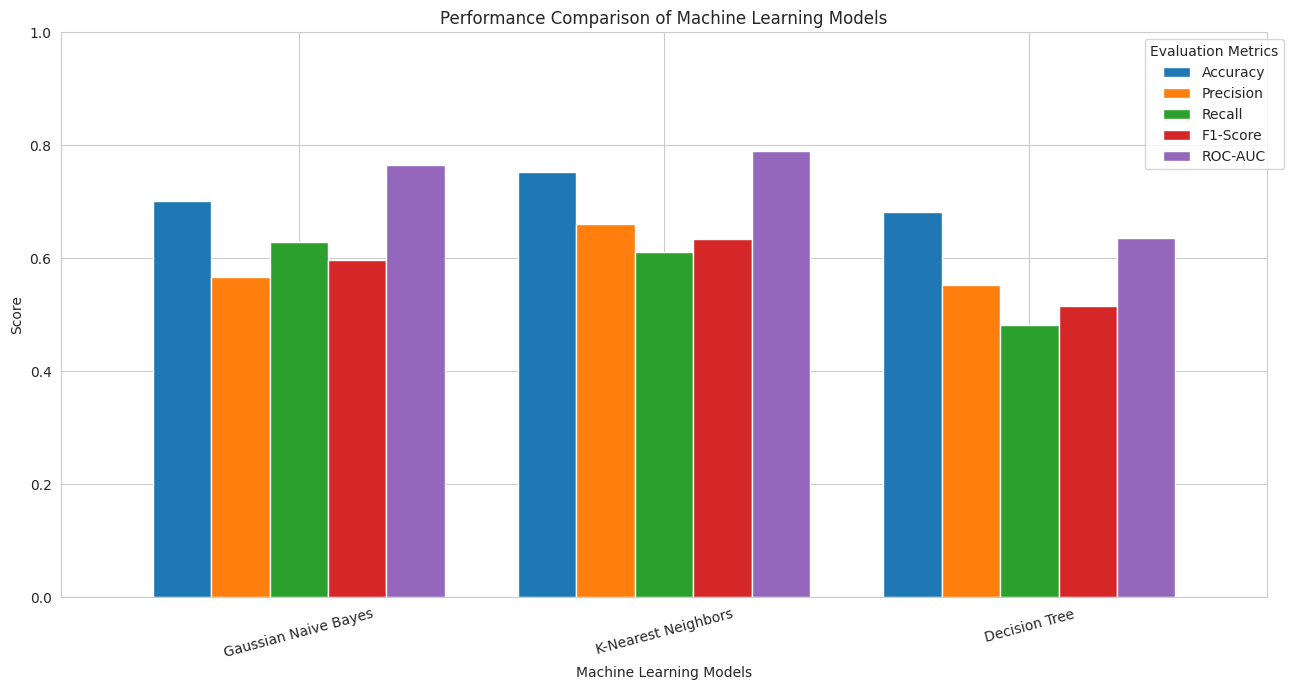

In [34]:

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC'
]

comparison_plot = results_df.set_index('Model')[metrics]

comparison_plot.plot(
    kind='bar',
    figsize=(13, 7),
    width=0.8
)

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(title='Evaluation Metrics', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


## 31. Confusion Matrix Analysis

A confusion matrix evaluates classification predictions by comparing actual and predicted class labels.

It contains four components:

- True Positive (TP): Diabetic patients correctly predicted as diabetic.
- True Negative (TN): Non-diabetic patients correctly predicted as non-diabetic.
- False Positive (FP): Non-diabetic patients incorrectly predicted as diabetic.
- False Negative (FN): Diabetic patients incorrectly predicted as non-diabetic.

Confusion matrices are generated for all three models to examine their classification errors.

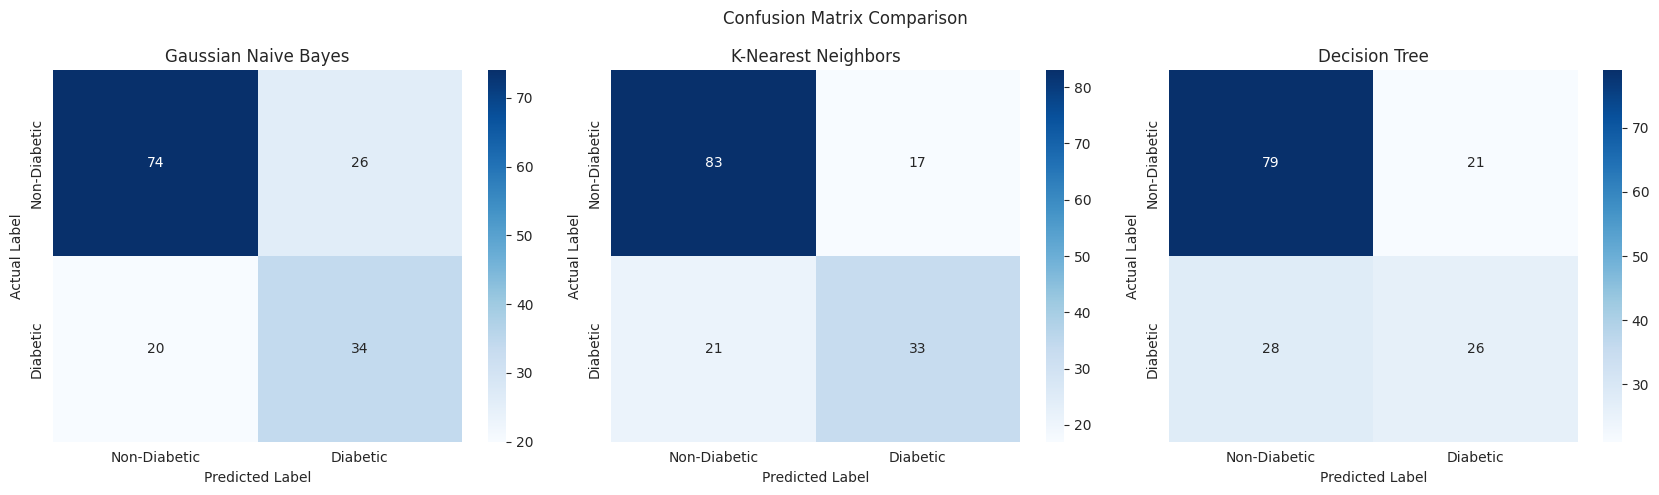

In [35]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (model_name, y_pred) in zip(
    axes, predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Non-Diabetic', 'Diabetic'],
        yticklabels=['Non-Diabetic', 'Diabetic'],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()


## 32. Detailed Classification Reports

Classification reports provide precision, recall, F1-score, and support for each target class.

This analysis is particularly useful for understanding whether a model performs differently when identifying diabetic and non-diabetic patients.

In [36]:

for model_name, y_pred in predictions.items():

    print("\n" + "=" * 60)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 60)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=['Non-Diabetic', 'Diabetic'],
            zero_division=0
        )
    )



CLASSIFICATION REPORT: Gaussian Naive Bayes
              precision    recall  f1-score   support

Non-Diabetic       0.79      0.74      0.76       100
    Diabetic       0.57      0.63      0.60        54

    accuracy                           0.70       154
   macro avg       0.68      0.68      0.68       154
weighted avg       0.71      0.70      0.70       154


CLASSIFICATION REPORT: K-Nearest Neighbors
              precision    recall  f1-score   support

Non-Diabetic       0.80      0.83      0.81       100
    Diabetic       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154


CLASSIFICATION REPORT: Decision Tree
              precision    recall  f1-score   support

Non-Diabetic       0.74      0.79      0.76       100
    Diabetic       0.55      0.48      0.51        54

    accuracy                           0.68       154
 

## 33. ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve illustrates the relationship between the true positive rate and false positive rate at different classification thresholds.

The Area Under the Curve (AUC) summarizes the model's ability to distinguish between the two classes. A higher AUC generally indicates better discrimination.

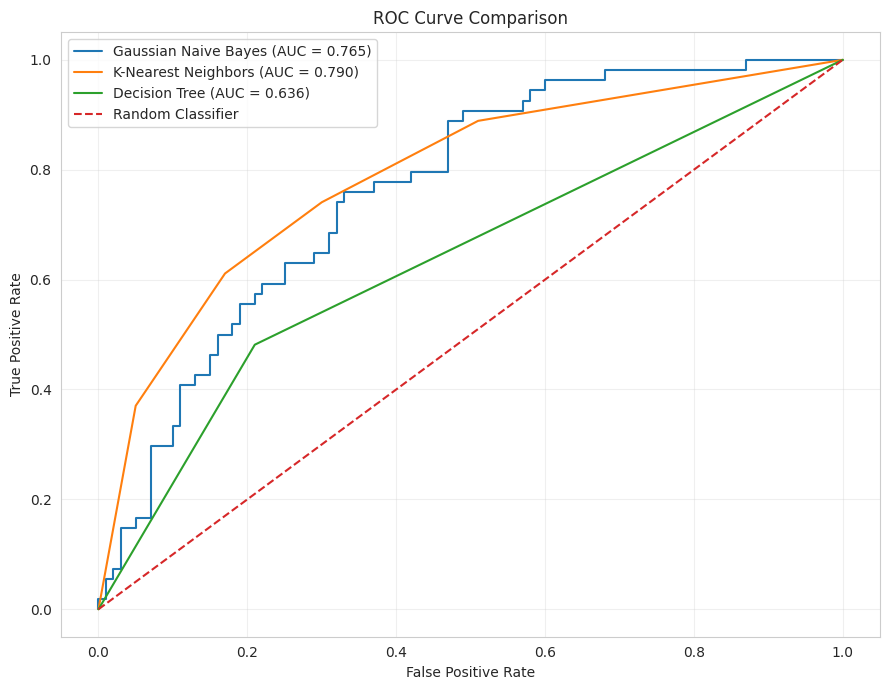

In [37]:

plt.figure(figsize=(9, 7))

for model_name, y_prob in prediction_probabilities.items():

    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{model_name} (AUC = {auc_value:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

In [40]:

# ==========================================
# HYPERPARAMETER TUNING CONFIGURATION
# ==========================================

models_and_params = {

    'Gaussian Naive Bayes': {
        'pipeline': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('model', GaussianNB())
        ]),
        'params': {
            'model__var_smoothing': np.logspace(-12, -6, 15)
        }
    },

    'K-Nearest Neighbors': {
        'pipeline': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
            ('model', KNeighborsClassifier())
        ]),
        'params': {
            'model__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17],
            'model__weights': ['uniform', 'distance'],
            'model__metric': ['euclidean', 'manhattan', 'minkowski'],
            'model__p': [1, 2]
        }
    },

    'Decision Tree': {
        'pipeline': Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('model', DecisionTreeClassifier(random_state=42))
        ]),
        'params': {
            'model__criterion': ['gini', 'entropy', 'log_loss'],
            'model__max_depth': [3, 4, 5, 6, 8, 10, None],
            'model__min_samples_split': [2, 5, 10, 15],
            'model__min_samples_leaf': [1, 2, 4, 6],
            'model__class_weight': [None, 'balanced']
        }
    }
}


In [41]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuned_models = {}
tuning_results = {}

for model_name, config in models_and_params.items():

    print(f"\nTuning {model_name}...")

    grid_search = GridSearchCV(
        estimator=config['pipeline'],
        param_grid=config['params'],
        scoring='f1',
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    tuned_models[model_name] = grid_search.best_estimator_

    tuning_results[model_name] = {
        'Best CV F1-Score': grid_search.best_score_,
        'Best Parameters': grid_search.best_params_
    }

    print("Best CV F1-Score:", round(grid_search.best_score_, 4))
    print("Best Parameters:", grid_search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results).T
display(tuning_results_df)



Tuning Gaussian Naive Bayes...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best CV F1-Score: 0.6369
Best Parameters: {'model__var_smoothing': np.float64(1e-12)}

Tuning K-Nearest Neighbors...
Fitting 5 folds for each of 96 candidates, totalling 480 fits
Best CV F1-Score: 0.6532
Best Parameters: {'model__metric': 'euclidean', 'model__n_neighbors': 13, 'model__p': 1, 'model__weights': 'uniform'}

Tuning Decision Tree...
Fitting 5 folds for each of 672 candidates, totalling 3360 fits
Best CV F1-Score: 0.6627
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 10}


,Best CV F1-Score,Best Parameters
Gaussian Naive Bayes,0.636877,{'model__var_smoothing': 1e-12}
K-Nearest Neighbors,0.653198,"{'model__metric': 'euclidean', 'model__n_neigh..."
Decision Tree,0.662666,"{'model__class_weight': 'balanced', 'model__cr..."


In [42]:

tuned_predictions = {}
tuned_probabilities = {}
tuned_results = []

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tuned_predictions[model_name] = y_pred
    tuned_probabilities[model_name] = y_prob

    tuned_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(
    tuned_results_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gaussian Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
1,K-Nearest Neighbors,0.7143,0.6087,0.5185,0.5600,0.7944
2,Decision Tree,0.7273,0.6111,0.6111,0.6111,0.7706


In [43]:

comparison_df = results_df.merge(
    tuned_results_df,
    on='Model',
    suffixes=('_Before', '_After')
)

display(comparison_df.round(4))


,Model,Accuracy_Before,Precision_Before,Recall_Before,F1-Score_Before,ROC-AUC_Before,Accuracy_After,Precision_After,Recall_After,F1-Score_After,ROC-AUC_After
0,Gaussian Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646,0.7013,0.5667,0.6296,0.5965,0.7646
1,K-Nearest Neighbors,0.7532,0.6600,0.6111,0.6346,0.7899,0.7143,0.6087,0.5185,0.5600,0.7944
2,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357,0.7273,0.6111,0.6111,0.6111,0.7706


### Accuracy-Based Model Tuning

These results are used to compare the models optimized for accuracy with the models optimized for F1-score. Since the dataset is imbalanced, accuracy alone may not give a reliable indication of model performance.

In [44]:

accuracy_tuned_models = {}
accuracy_tuning_results = []

for model_name, config in models_and_params.items():

    print(f"\nOptimizing accuracy for {model_name}...")

    grid_search = GridSearchCV(
        estimator=config['pipeline'],
        param_grid=config['params'],
        scoring='accuracy',
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    accuracy_tuned_models[model_name] = grid_search.best_estimator_

    accuracy_tuning_results.append({
        'Model': model_name,
        'Best CV Accuracy': grid_search.best_score_,
        'Best Parameters': grid_search.best_params_
    })

accuracy_tuning_df = pd.DataFrame(accuracy_tuning_results)

display(accuracy_tuning_df.round(4))



Optimizing accuracy for Gaussian Naive Bayes...
Fitting 5 folds for each of 15 candidates, totalling 75 fits

Optimizing accuracy for K-Nearest Neighbors...
Fitting 5 folds for each of 96 candidates, totalling 480 fits

Optimizing accuracy for Decision Tree...
Fitting 5 folds for each of 672 candidates, totalling 3360 fits


,Model,Best CV Accuracy,Best Parameters
0,Gaussian Naive Bayes,0.7623,{'model__var_smoothing': 1e-12}
1,K-Nearest Neighbors,0.7752,"{'model__metric': 'euclidean', 'model__n_neigh..."
2,Decision Tree,0.7443,"{'model__class_weight': None, 'model__criterio..."


In [45]:

accuracy_optimized_results = []

for model_name, model in accuracy_tuned_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    accuracy_optimized_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

accuracy_optimized_df = pd.DataFrame(accuracy_optimized_results)

display(accuracy_optimized_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gaussian Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
1,K-Nearest Neighbors,0.7143,0.6087,0.5185,0.5600,0.7944
2,Decision Tree,0.6883,0.6364,0.2593,0.3684,0.7641


## 34. Best Model Selection

The three trained machine learning models are compared using their evaluation metrics.

For this diabetes classification task, F1-score and recall are given particular importance, because identifying actual diabetic observations is important.

The model with the highest F1-score is selected as the initial best-performing model. Recall and ROC-AUC are also considered when interpreting the results.

The selected model will subsequently be used for explainability analysis.

In [46]:

# Rank models by F1-score, then recall, then ROC-AUC
ranked_results = results_df.sort_values(
    by=['F1-Score', 'Recall', 'ROC-AUC'],
    ascending=False
).reset_index(drop=True)

print("MODEL RANKING")
display(ranked_results.round(4))

# Select best model
best_model_name = ranked_results.loc[0, 'Model']
best_model = trained_models[best_model_name]

best_predictions = predictions[best_model_name]
best_probabilities = prediction_probabilities[best_model_name]

print("\nSelected Best Model:", best_model_name)

print("\nBest Model Performance:")
display(
    results_df[results_df['Model'] == best_model_name]
    .round(4)
)


MODEL RANKING


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,K-Nearest Neighbors,0.7532,0.6600,0.6111,0.6346,0.7899
1,Gaussian Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
2,Decision Tree,0.6818,0.5532,0.4815,0.5149,0.6357



Selected Best Model: K-Nearest Neighbors

Best Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,K-Nearest Neighbors,0.7532,0.66,0.6111,0.6346,0.7899


In [47]:

all_experiments = []

# Original models
for name in trained_models:
    all_experiments.append({
        'Model': name,
        'Experiment': 'Original',
        **{
            metric: results_df.loc[
                results_df['Model'] == name, metric
            ].iloc[0]
            for metric in [
                'Accuracy', 'Precision', 'Recall',
                'F1-Score', 'ROC-AUC'
            ]
        }
    })

# F1-score optimized models
for name in tuned_models:
    all_experiments.append({
        'Model': name,
        'Experiment': 'F1 Optimized',
        **{
            metric: tuned_results_df.loc[
                tuned_results_df['Model'] == name, metric
            ].iloc[0]
            for metric in [
                'Accuracy', 'Precision', 'Recall',
                'F1-Score', 'ROC-AUC'
            ]
        }
    })

# Accuracy optimized models
for name in accuracy_tuned_models:
    all_experiments.append({
        'Model': name,
        'Experiment': 'Accuracy Optimized',
        **{
            metric: accuracy_optimized_df.loc[
                accuracy_optimized_df['Model'] == name, metric
            ].iloc[0]
            for metric in [
                'Accuracy', 'Precision', 'Recall',
                'F1-Score', 'ROC-AUC'
            ]
        }
    })

final_comparison_df = pd.DataFrame(all_experiments)

display(final_comparison_df.round(4))


,Model,Experiment,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gaussian Naive Bayes,Original,0.7013,0.5667,0.6296,0.5965,0.7646
1,K-Nearest Neighbors,Original,0.7532,0.6600,0.6111,0.6346,0.7899
2,Decision Tree,Original,0.6818,0.5532,0.4815,0.5149,0.6357
3,Gaussian Naive Bayes,F1 Optimized,0.7013,0.5667,0.6296,0.5965,0.7646
4,K-Nearest Neighbors,F1 Optimized,0.7143,0.6087,0.5185,0.5600,0.7944
5,Decision Tree,F1 Optimized,0.7273,0.6111,0.6111,0.6111,0.7706
6,Gaussian Naive Bayes,Accuracy Optimized,0.7013,0.5667,0.6296,0.5965,0.7646
7,K-Nearest Neighbors,Accuracy Optimized,0.7143,0.6087,0.5185,0.5600,0.7944
8,Decision Tree,Accuracy Optimized,0.6883,0.6364,0.2593,0.3684,0.7641


## 35. Saving the Selected Machine Learning Model

The selected model and its preprocessing components are saved using Joblib. This allows the trained model to be reused without repeating the entire training process.

We save the imputer and scaler alongside the model because future predictions must use the same preprocessing transformations.

### Model Saving

This section saves the trained KNN model and its preprocessing components for future use. The same saving process is also performed later in the notebook, so only one saving section is needed to avoid repeating the steps.

In [48]:

from sklearn.pipeline import Pipeline
import joblib
import os

# Recreate the original KNN as a complete pipeline
final_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Train using the original training data
final_model.fit(X_train, y_train)

# Save the complete pipeline
os.makedirs('/content/diabetes_model', exist_ok=True)

joblib.dump(
    final_model,
    '/content/diabetes_model/final_diabetes_model.pkl'
)

print("Final Model: Original K-Nearest Neighbors")
print("Test Accuracy:", accuracy_score(
    y_test, final_model.predict(X_test)
))
print("Model saved successfully!")


Final Model: Original K-Nearest Neighbors
Test Accuracy: 0.7532467532467533
Model saved successfully!


## 36. Explainable AI Using SHAP

SHAP (SHapley Additive exPlanations) is used to understand how individual input features influence the machine learning model's predictions.

It helps identify which health-related factors contribute most to diabetes prediction. SHAP summary plots and dependence plots are used to interpret the model's behavior and feature importance.

In [49]:

!pip install shap -q

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("SHAP version:", shap.__version__)


SHAP version: 0.54.1


In [50]:

# Background data for SHAP
X_background = X_train.sample(
    n=min(40, len(X_train)),
    random_state=42
)

# Records to explain
X_explain = X_test.sample(
    n=min(20, len(X_test)),
    random_state=42
)

print("Background dataset:", X_background.shape)
print("Explanation dataset:", X_explain.shape)


Background dataset: (40, 8)
Explanation dataset: (20, 8)


In [51]:

# Explain the probability of the diabetic class (class 1)
explainer = shap.KernelExplainer(
    lambda data: final_model.predict_proba(
        pd.DataFrame(data, columns=X_train.columns)
    )[:, 1],
    X_background
)

print("SHAP explainer created successfully!")


SHAP explainer created successfully!


In [52]:

shap_values = explainer.shap_values(
    X_explain,
    nsamples=100
)

shap_values = np.asarray(shap_values)

# Handle different SHAP output formats
if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 0]

print("SHAP values calculated!")
print("SHAP shape:", shap_values.shape)


  0%|          | 0/20 [00:00<?, ?it/s]

SHAP values calculated!
SHAP shape: (20, 8)


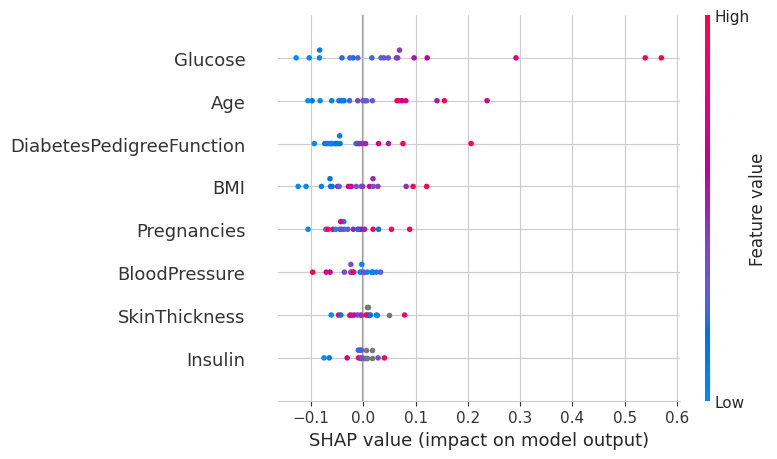

In [53]:

shap.summary_plot(
    shap_values,
    X_explain,
    feature_names=X_train.columns
)


,Feature,Mean Absolute SHAP Value
1,Glucose,0.1227
7,Age,0.0679
6,DiabetesPedigreeFunction,0.0542
5,BMI,0.0522
0,Pregnancies,0.0414
2,BloodPressure,0.0255
3,SkinThickness,0.0249
4,Insulin,0.0170


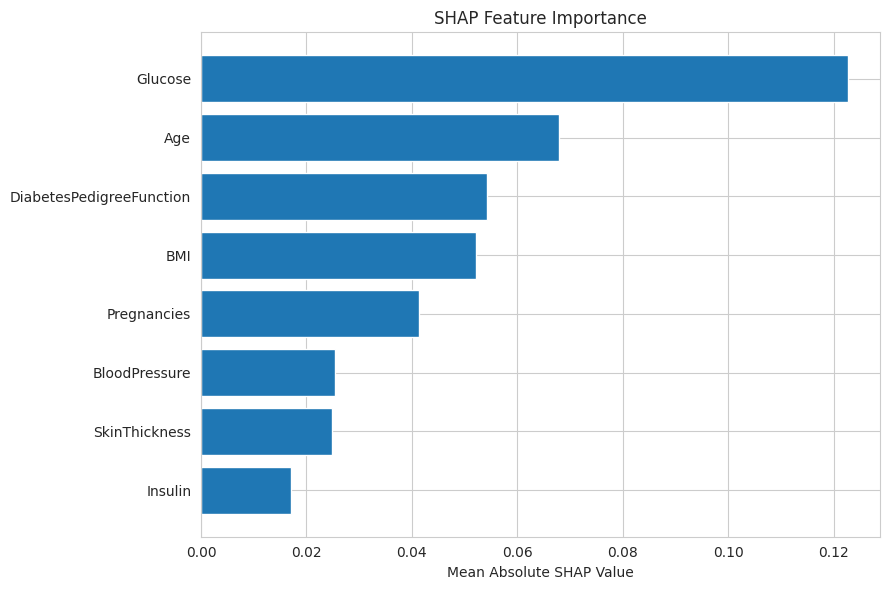

In [54]:

shap_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Mean Absolute SHAP Value': np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by='Mean Absolute SHAP Value',
    ascending=False
)

display(shap_importance.round(4))

plt.figure(figsize=(9, 6))
plt.barh(
    shap_importance['Feature'],
    shap_importance['Mean Absolute SHAP Value']
)
plt.gca().invert_yaxis()
plt.xlabel('Mean Absolute SHAP Value')
plt.title('SHAP Feature Importance')
plt.tight_layout()
plt.show()


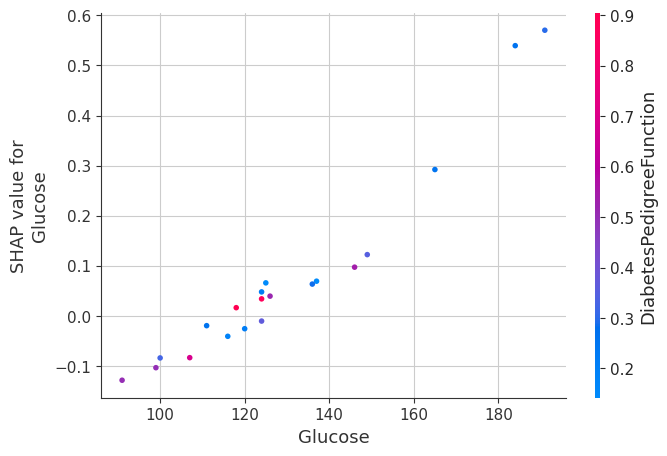

In [55]:

# Select the most important feature
top_feature = shap_importance.iloc[0]['Feature']

shap.dependence_plot(
    top_feature,
    shap_values,
    X_explain,
    feature_names=X_train.columns
)


## 37. Local Model Explanation Using LIME

LIME (Local Interpretable Model-Agnostic Explanations) explains individual predictions made by the machine learning model.

It shows how different input features influence a particular patient's prediction and helps make the model's decisions easier to understand.

In [56]:

!pip install lime -q

from lime.lime_tabular import LimeTabularExplainer

print("LIME installed and imported successfully!")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
LIME installed and imported successfully!


In [57]:

lime_explainer = LimeTabularExplainer(
    training_data=X_train_scaled.values,
    feature_names=list(X_train.columns),
    class_names=['Non-Diabetic', 'Diabetic'],
    mode='classification',
    discretize_continuous=True,
    random_state=42
)

print("LIME explainer created successfully!")


LIME explainer created successfully!


In [58]:

sample_index = 0

patient_data = X_test_scaled.iloc[sample_index].values

actual_value = y_test.iloc[sample_index]

predicted_value = final_model.predict(
    X_test.iloc[[sample_index]]
)[0]

predicted_probability = final_model.predict_proba(
    X_test.iloc[[sample_index]]
)[0]

print("Actual Outcome:", actual_value)
print("Predicted Outcome:", predicted_value)
print("Probability of Non-Diabetic:", round(predicted_probability[0], 4))
print("Probability of Diabetic:", round(predicted_probability[1], 4))


Actual Outcome: 0
Predicted Outcome: 1
Probability of Non-Diabetic: 0.4
Probability of Diabetic: 0.6


In [59]:

lime_explanation = lime_explainer.explain_instance(
    data_row=patient_data,
    predict_fn=final_model.named_steps['classifier'].predict_proba,
    num_features=8,
    num_samples=1000
)

lime_explanation.show_in_notebook(show_table=True)


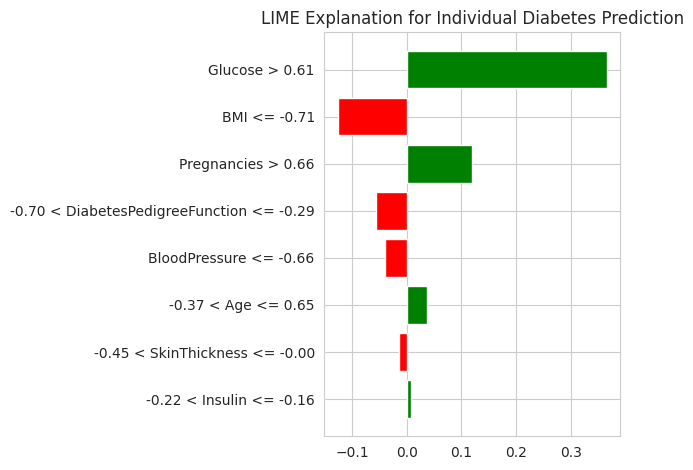

In [60]:

fig = lime_explanation.as_pyplot_figure()

plt.title("LIME Explanation for Individual Diabetes Prediction")
plt.tight_layout()
plt.show()


In [61]:

lime_results = pd.DataFrame(
    lime_explanation.as_list(),
    columns=['Feature Condition', 'Contribution']
)

display(lime_results)


,Feature Condition,Contribution
0,Glucose > 0.61,0.365614
1,BMI <= -0.71,-0.125512
2,Pregnancies > 0.66,0.119894
3,-0.70 < DiabetesPedigreeFunction <= -0.29,-0.055727
4,BloodPressure <= -0.66,-0.039878
5,-0.37 < Age <= 0.65,0.038177
6,-0.45 < SkinThickness <= -0.00,-0.014445
7,-0.22 < Insulin <= -0.16,0.008740


## 38. Age Group-Based Performance Analysis

In this section, the model's predictions are analyzed across different age groups.

The analysis compares actual and predicted outcomes and evaluates model performance using Accuracy, Precision, Recall, and F1-score for each age group.

In [62]:

# Predict using the final model
age_predictions = final_model.predict(X_test)

# Combine actual outcomes, predictions and age
age_analysis = pd.DataFrame({
    'Age': X_test['Age'].values,
    'Actual': y_test.values,
    'Predicted': age_predictions
})

# Create age groups
age_analysis['Age Group'] = pd.cut(
    age_analysis['Age'],
    bins=[0, 30, 45, 60, 100],
    labels=['Below 30', '30–45', '46–60', 'Above 60']
)

age_group_results = []

for group, data in age_analysis.groupby('Age Group', observed=True):

    if len(data) == 0:
        continue

    age_group_results.append({
        'Age Group': group,
        'Sample Count': len(data),
        'Accuracy': accuracy_score(data['Actual'], data['Predicted']),
        'Precision': precision_score(
            data['Actual'], data['Predicted'], zero_division=0
        ),
        'Recall': recall_score(
            data['Actual'], data['Predicted'], zero_division=0
        ),
        'F1-Score': f1_score(
            data['Actual'], data['Predicted'], zero_division=0
        )
    })

age_group_df = pd.DataFrame(age_group_results)

display(age_group_df.round(4))


,Age Group,Sample Count,Accuracy,Precision,Recall,F1-Score
0,Below 30,89,0.7978,0.5000,0.3889,0.4375
1,30–45,40,0.7000,0.8182,0.6923,0.7500
2,46–60,20,0.7000,0.6154,0.8889,0.7273
3,Above 60,5,0.6000,0.0000,0.0000,0.0000


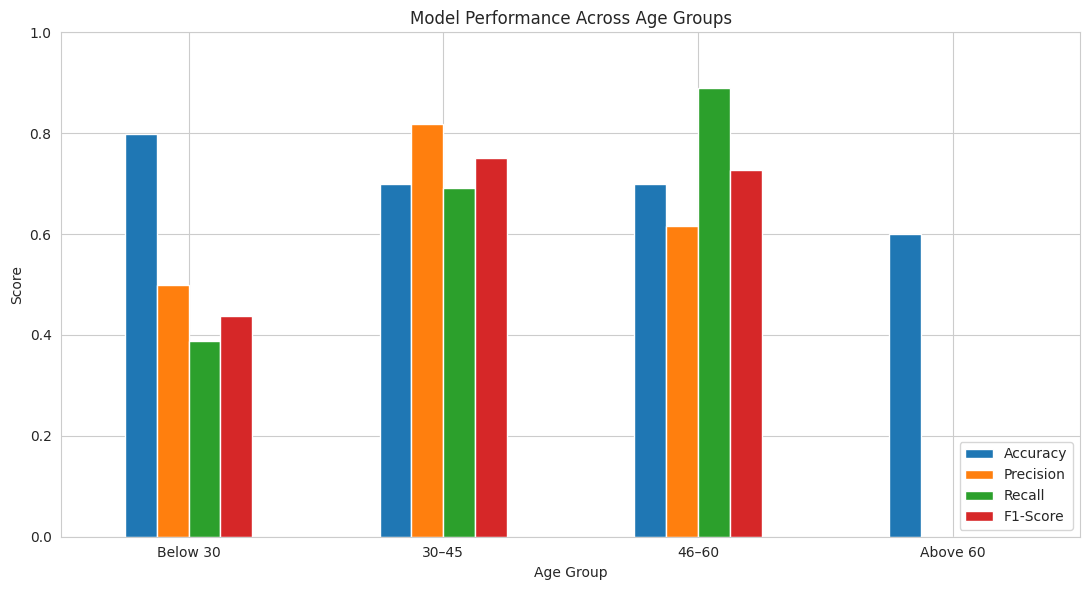

In [63]:

age_group_df.set_index('Age Group')[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Model Performance Across Age Groups')
plt.ylabel('Score')
plt.xlabel('Age Group')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [64]:
# Check the number of patients and actual/predicted classes in each age group

print("Age Group Sample Counts:")
print(age_analysis['Age Group'].value_counts())

print("\nDetailed Age Group Analysis:")
print(age_analysis.groupby('Age Group', observed=False).agg(
    Total_Patients=('Actual', 'count'),
    Actual_Diabetic=('Actual', 'sum'),
    Predicted_Diabetic=('Predicted', 'sum')
))

Age Group Sample Counts:
Age Group
Below 30    89
30–45       40
46–60       20
Above 60     5
Name: count, dtype: int64

Detailed Age Group Analysis:
           Total_Patients  Actual_Diabetic  Predicted_Diabetic
Age Group                                                     
Below 30               89               18                  14
30–45                  40               26                  22
46–60                  20                9                  13
Above 60                5                1                   1


### Final Confusion Matrix and Classification Report

In this section, the selected machine learning model is evaluated using a confusion matrix and classification report.

The confusion matrix shows the number of correctly and incorrectly classified diabetic and non-diabetic patients. The classification report provides precision, recall, and F1-score for both classes.

These evaluation methods help us understand the model's ability to identify diabetic patients and distinguish them from non-diabetic patients.

**Objective:** To examine the final classification performance of the selected model.

In [65]:
# Generate predictions using the selected model

final_model = trained_models[best_model_name]

y_final_pred = final_model.predict(X_test_scaled)
y_final_prob = final_model.predict_proba(X_test_scaled)[:, 1]

print("Selected Model:", best_model_name)
print("Final predictions generated successfully.")

Selected Model: K-Nearest Neighbors
Final predictions generated successfully.


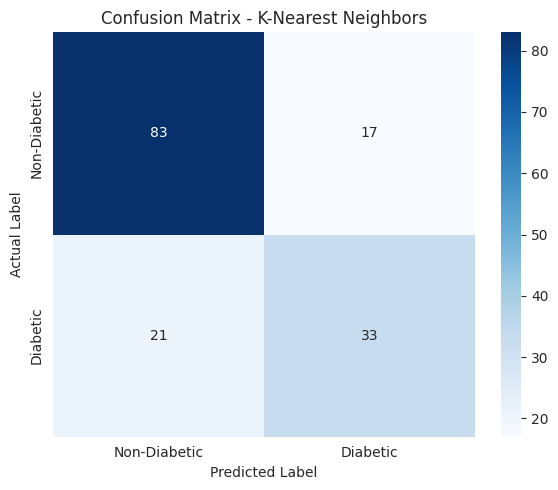

In [66]:
# Generate the confusion matrix

cm = confusion_matrix(y_test, y_final_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

In [67]:
# Generate the classification report

report = classification_report(
    y_test,
    y_final_pred,
    target_names=['Non-Diabetic', 'Diabetic'],
    zero_division=0
)

print(f"Classification Report - {best_model_name}\n")
print(report)

Classification Report - K-Nearest Neighbors

              precision    recall  f1-score   support

Non-Diabetic       0.80      0.83      0.81       100
    Diabetic       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [68]:
# Extract TP, TN, FP and FN

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix Interpretation:")
print("True Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

Confusion Matrix Interpretation:
True Negatives (TN): 83
False Positives (FP): 17
False Negatives (FN): 21
True Positives (TP): 33


### Limitations of the Project

1. **Dataset Size:** The Pima Indians Diabetes dataset contains only 768 records, which may limit the generalization ability of the trained models.

2. **Dataset Representation:** The dataset represents a specific population and may not reflect diabetes patterns across all demographic groups.

3. **Class Imbalance:** The dataset contains more non-diabetic records than diabetic records, which can affect model performance.

4. **Missing and Invalid Values:** Several zero values in medical features such as Glucose, Blood Pressure, Insulin, Skin Thickness, and BMI were treated as missing values and imputed using the median.

5. **Model Performance:** The selected KNN model achieved approximately 75% accuracy, but its recall indicates that some diabetic cases were incorrectly classified as non-diabetic.

6. **Medical Reliability:** The model is developed for academic and educational purposes and cannot replace professional medical testing or diagnosis.

### Future Scope

1. **Larger Datasets:** The model can be trained and evaluated using larger and more diverse healthcare datasets.

2. **Advanced Algorithms:** Additional algorithms such as Random Forest, XGBoost, and ensemble learning can be explored.

3. **Model Optimization:** Further hyperparameter tuning and threshold optimization may improve the balance between precision and recall.

4. **Explainable AI:** SHAP and LIME can help users understand the features influencing individual predictions.

5. **Web Application:** The trained model can be integrated into a Streamlit application to provide an interactive prediction interface.

6. **External Validation:** The model should be tested on independent datasets before considering any real-world healthcare application.

### Conclusion

This project developed a machine learning-based system for predicting diabetes using the Pima Indians Diabetes dataset. The workflow included data inspection, exploratory data analysis, handling invalid zero values, preprocessing, model development, and performance evaluation.

Three machine learning algorithms—Gaussian Naive Bayes, K-Nearest Neighbors, and Decision Tree—were implemented and compared using accuracy, precision, recall, F1-score, and ROC-AUC. Among the original models, KNN achieved the best reported test accuracy of approximately 75.32%.

SHAP and LIME were incorporated to improve model interpretability, while age-group analysis was performed to examine model performance across different age categories.

Overall, the project demonstrates how machine learning and explainable AI techniques can support diabetes risk prediction. However, the model is intended for academic purposes and should not be considered a medical diagnostic system.

### Saving the Final Machine Learning Model

In this section, the selected K-Nearest Neighbors model is saved using Joblib. The trained model includes the preprocessing pipeline required to handle missing values and scale input features.

Saving the complete pipeline allows the same preprocessing operations to be applied when making predictions on new patient records.

In [69]:
import joblib
import os

# Create the final KNN pipeline
final_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Train the final model
final_model.fit(X_train, y_train)

print("Final KNN model trained successfully.")

Final KNN model trained successfully.


In [70]:
# Create a folder for the final model
os.makedirs('/content/diabetes_model', exist_ok=True)

# Save the complete pipeline
model_path = '/content/diabetes_model/final_diabetes_model.pkl'

joblib.dump(final_model, model_path)

print("Model saved successfully at:", model_path)

Model saved successfully at: /content/diabetes_model/final_diabetes_model.pkl


In [71]:
# Load the saved model and verify it

loaded_model = joblib.load(model_path)

print("Saved model loaded successfully.")

print("Test Accuracy:",
      accuracy_score(y_test, loaded_model.predict(X_test)))

Saved model loaded successfully.
Test Accuracy: 0.7532467532467533


### Saving the Trained Model to Google Drive

The trained machine learning pipeline is saved to Google Drive so that it remains available even after the Google Colab runtime is disconnected or restarted. The saved model can later be loaded into the Streamlit application for making predictions on new patient data.

In [72]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [73]:
import os
import shutil

# Create project folder in Google Drive
drive_folder = '/content/drive/MyDrive/Diabetes_Prediction_Project'
os.makedirs(drive_folder, exist_ok=True)

# Copy the trained model to Google Drive
shutil.copy(
    '/content/diabetes_model/final_diabetes_model.pkl',
    drive_folder
)

print("Final model saved successfully in Google Drive.")
print("Location:", drive_folder)

Final model saved successfully in Google Drive.
Location: /content/drive/MyDrive/Diabetes_Prediction_Project


In [74]:
saved_model_path = os.path.join(
    drive_folder,
    'final_diabetes_model.pkl'
)

print("Model exists:", os.path.exists(saved_model_path))
print("Model size:", round(os.path.getsize(saved_model_path) / 1024, 2), "KB")

Model exists: True
Model size: 93.92 KB


### Streamlit-Based Diabetes Prediction Application

This section develops an interactive web application using Streamlit. The application uses the trained K-Nearest Neighbors model saved in the previous section.

Users can enter eight health-related features, submit the information, and view the predicted diabetes class along with the model's estimated class probabilities.

The application is designed for educational demonstration and is not a substitute for professional medical diagnosis.

In [75]:
import numpy as np
import pandas as pd
import joblib

# Load the trained model
model_path = "/content/drive/MyDrive/Diabetes_Prediction_Project/final_diabetes_model.pkl"
model = joblib.load(model_path)

print("Diabetes Prediction System")
print("-" * 40)

# Take input from the user
pregnancies = float(input("Enter number of pregnancies: "))
glucose = float(input("Enter glucose level: "))
blood_pressure = float(input("Enter blood pressure: "))
skin_thickness = float(input("Enter skin thickness: "))
insulin = float(input("Enter insulin level: "))
bmi = float(input("Enter BMI: "))
diabetes_pedigree = float(input("Enter diabetes pedigree function: "))
age = float(input("Enter age: "))

# Prepare input in the correct feature order
input_data = pd.DataFrame([[
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age
]], columns=[
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
])

# Convert medically invalid zero values into missing values
zero_missing_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

input_data[zero_missing_columns] = input_data[zero_missing_columns].replace(0, np.nan)

# Make prediction
prediction = model.predict(input_data)[0]
probability = model.predict_proba(input_data)[0][1]

# Display result
print("\n" + "=" * 40)
print("DIABETES PREDICTION RESULT")
print("=" * 40)

if prediction == 1:
    print("Prediction: Diabetes detected by the model.")
else:
    print("Prediction: Diabetes not detected by the model.")

print(f"Estimated diabetes probability: {probability * 100:.2f}%")
print("=" * 40)

print("\nNote: This is an ML model prediction, not a medical diagnosis.")

Diabetes Prediction System
----------------------------------------
Enter number of pregnancies: 4
Enter glucose level: 175
Enter blood pressure: 85
Enter skin thickness: 32
Enter insulin level: 150
Enter BMI: 34
Enter diabetes pedigree function: 0.75
Enter age: 45

DIABETES PREDICTION RESULT
Prediction: Diabetes detected by the model.
Estimated diabetes probability: 100.00%

Note: This is an ML model prediction, not a medical diagnosis.


In [76]:
import numpy as np
import pandas as pd
import joblib

# Load the trained model
model_path = "/content/drive/MyDrive/Diabetes_Prediction_Project/final_diabetes_model.pkl"
model = joblib.load(model_path)

print("Diabetes Prediction System")
print("-" * 40)

# Take input from the user
pregnancies = float(input("Enter number of pregnancies: "))
glucose = float(input("Enter glucose level: "))
blood_pressure = float(input("Enter blood pressure: "))
skin_thickness = float(input("Enter skin thickness: "))
insulin = float(input("Enter insulin level: "))
bmi = float(input("Enter BMI: "))
diabetes_pedigree = float(input("Enter diabetes pedigree function: "))
age = float(input("Enter age: "))

# Prepare input in the correct feature order
input_data = pd.DataFrame([[
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age
]], columns=[
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
])

# Convert medically invalid zero values into missing values
zero_missing_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

input_data[zero_missing_columns] = input_data[zero_missing_columns].replace(0, np.nan)

# Make prediction
prediction = model.predict(input_data)[0]
probability = model.predict_proba(input_data)[0][1]

# Display result
print("\n" + "=" * 40)
print("DIABETES PREDICTION RESULT")
print("=" * 40)

if prediction == 1:
    print("Prediction: Diabetes detected by the model.")
else:
    print("Prediction: Diabetes not detected by the model.")

print(f"Estimated diabetes probability: {probability * 100:.2f}%")
print("=" * 40)

print("\nNote: This is an ML model prediction, not a medical diagnosis.")

Diabetes Prediction System
----------------------------------------
Enter number of pregnancies: 0
Enter glucose level: 120
Enter blood pressure: 65
Enter skin thickness: 20
Enter insulin level: 90
Enter BMI: 28
Enter diabetes pedigree function: 0.40
Enter age: 22

DIABETES PREDICTION RESULT
Prediction: Diabetes not detected by the model.
Estimated diabetes probability: 0.00%

Note: This is an ML model prediction, not a medical diagnosis.
